# Seminário de Andamento

## Comparação dos 4 baselines do ABCInML — Regressão Logística (monthly)

Análise a partir dos resultados agregados em `src/results/all/assessment_all_baselines.csv`.

- **Filtro:** `model_name == 'logistic_regression'` e `batch_type == 'monthly'`
- **Agregação:** as métricas são agregadas pela **média por batch** dentro de cada baseline (colapsando os diferentes runs: alphas, técnicas de forecasting e janelas)
- **Gráfico:** segue a mesma lógica de `metrics_utils._generate_comparative_chart` (médias móveis por baseline, um subplot por métrica, com os períodos epidemiológicos ao fundo)

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# O notebook vive em src/notebooks/ -> raiz do repo dois níveis acima
ROOT = Path.cwd().resolve()
while not (ROOT / 'src' / 'utils' / 'metrics_utils.py').exists():
    ROOT = ROOT.parent
sys.path.append(str(ROOT / 'src' / 'utils'))

import metrics_utils
from metrics_utils import _SNAPSHOT_METRICS

C:\master-degree-fairness-distribution_shifts\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Carrega os resultados agregados de todos os runs
assessment_df = pd.read_csv(ROOT / 'src' / 'results' / 'all' / 'assessment_all_baselines.csv')

# Filtro: apenas regressão logística, separada por tipo de batch
lr_df = assessment_df[assessment_df['model_name'] == 'logistic_regression']
lr_monthly_df = lr_df[lr_df['batch_type'] == 'monthly'].copy()
lr_weekly_df = lr_df[lr_df['batch_type'] == 'weekly'].copy()

print(f'Total de linhas (todos os runs): {len(assessment_df)}')
print(f'LR monthly: {len(lr_monthly_df)} linhas | LR weekly: {len(lr_weekly_df)} linhas')
lr_monthly_df.groupby('baseline').size()

Total de linhas (todos os runs): 52672
LR monthly: 4671 linhas | LR weekly: 21665 linhas


baseline
abcinml    4422
dynamic      83
static       83
vanilla      83
dtype: int64

### Agregação: média das métricas por batch

Os baselines `vanilla`, `static` e `dynamic` têm um run por batch; o `abcinml` tem vários (11 alphas × técnicas de forecasting × janelas). A média por `(baseline, batch)` colapsa essa variação — a mesma agregação feita internamente por `_generate_comparative_chart`.

In [3]:
metric_cols = [col for col, _ in _SNAPSHOT_METRICS]

mean_per_batch = (
    lr_monthly_df
    .groupby(['baseline', 'batch'], as_index=False)[metric_cols]
    .mean()
)

print(f'{len(mean_per_batch)} linhas (baseline x batch)')
mean_per_batch.head(10)

332 linhas (baseline x batch)


,baseline,batch,acc,auc,sp,tpr,fpr
0,abcinml,2019-04,0.906934,0.841955,0.047591,0.049865,0.014445
1,abcinml,2019-05,0.895694,0.842785,0.015581,0.128619,0.002947
2,abcinml,2019-06,0.882967,0.819962,0.005040,0.165251,0.005885
3,abcinml,2019-07,0.857265,0.819087,0.003538,0.179317,0.001114
4,abcinml,2019-08,0.872627,0.819275,0.019529,0.125984,0.006243
5,abcinml,2019-09,0.890947,0.824131,0.010234,0.165562,0.008493
6,abcinml,2019-10,0.885034,0.841054,0.022733,0.139652,0.008983
7,abcinml,2019-11,0.899180,0.852465,0.030563,0.199151,0.017645
8,abcinml,2019-12,0.875434,0.805355,0.011302,0.125782,0.008393
9,abcinml,2020-01,0.851097,0.801321,0.012949,0.049524,0.011493


In [4]:
# Resumo geral: média de cada métrica por baseline (sobre os batches)
(
    mean_per_batch
    .groupby('baseline')[metric_cols]
    .mean()
    .reindex(['vanilla', 'static', 'dynamic', 'abcinml'])
    .round(4)
)

,acc,auc,sp,tpr,fpr
baseline,,,,,
vanilla,0.8504,0.8153,0.2472,0.2867,0.1754
static,0.8520,0.7819,0.0715,0.0472,0.0323
dynamic,0.8681,0.8038,0.0464,0.1027,0.0085
abcinml,0.8669,0.7924,0.0391,0.1328,0.0072


### Gráfico comparativo dos 4 baselines — monthly e weekly

Duas fileiras de subplots (uma por `batch_type`), cada uma seguindo a mesma lógica de `metrics_utils._generate_comparative_chart`:
1. agrega as métricas pela média por `(baseline, batch)`;
2. aplica média móvel (5 batches para monthly, 20 para weekly — os padrões do pipeline);
3. restringe ao intervalo de batches comum a todos os baselines;
4. desenha um subplot por métrica (Accuracy, AUC-ROC, SP, TPR diff, FPR diff) com os períodos epidemiológicos ao fundo.

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\seminario\comparacao_baselines_lr.png


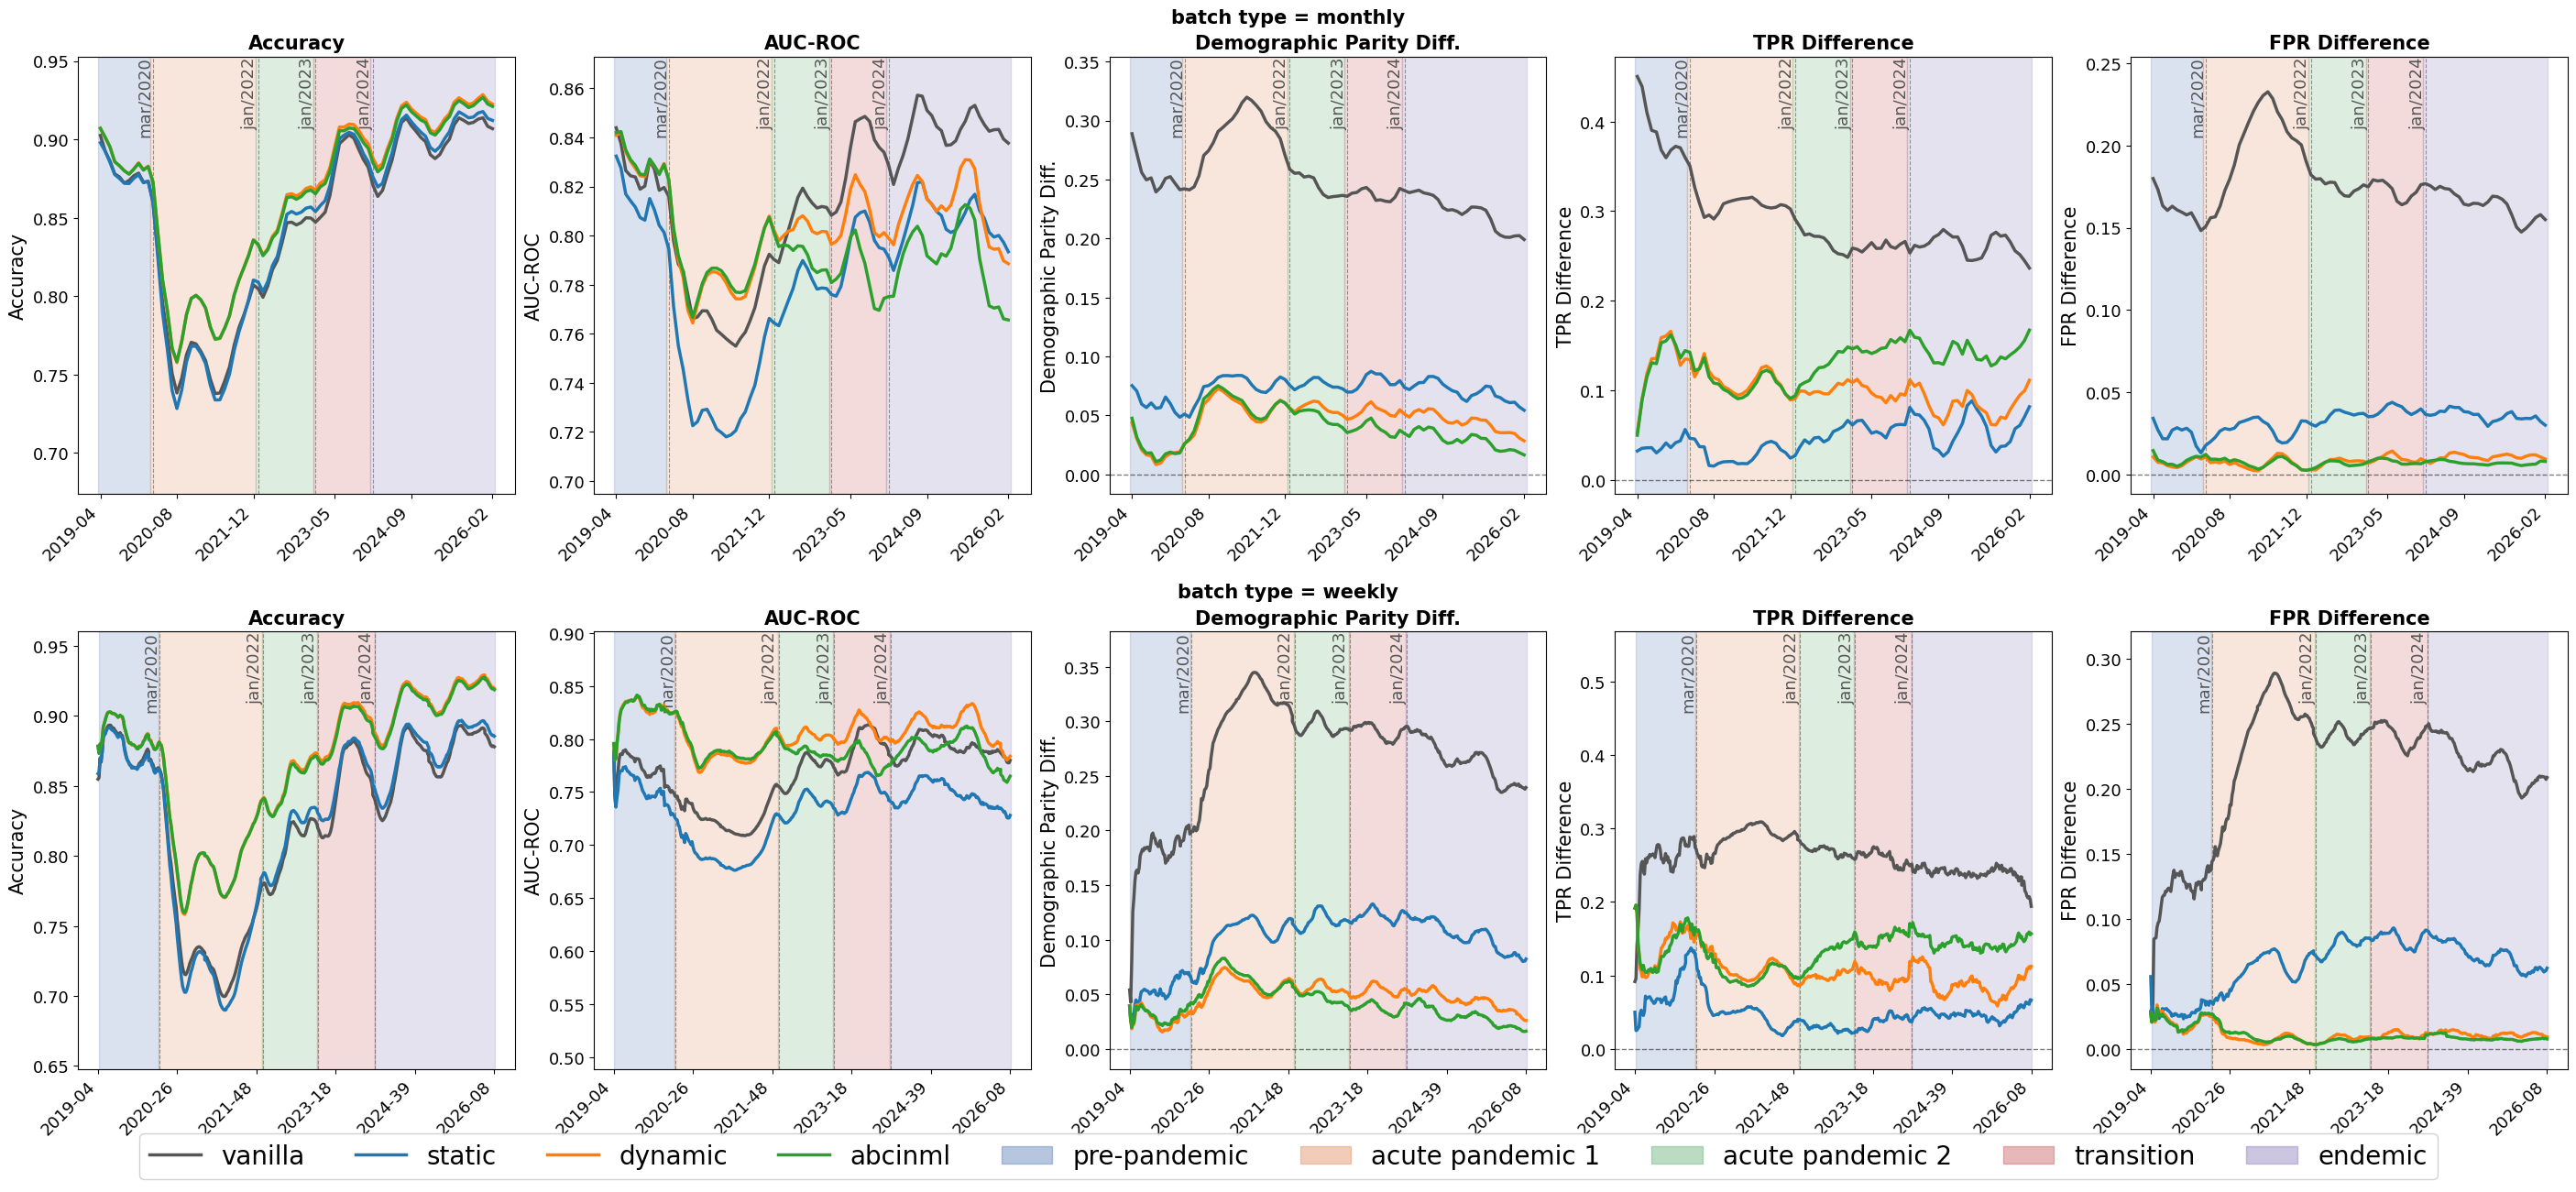

In [5]:
from metrics_utils import (
    _BASELINE_ORDER,
    _BASELINE_COLORS,
    _BATCH_FORMAT,
    _batch_to_datetime,
    _build_ma_series,
    _add_period_spans,
    _apply_bin_xticks,
)

PERIOD_LABELS_EN = {
    'pré-pandemia': 'pre-pandemic',
    'pandemia aguda 1': 'acute pandemic 1',
    'pandemia aguda 2': 'acute pandemic 2',
    'transição': 'transition',
    'endêmico': 'endemic',
}


def plot_baselines_row(axes, assessment_df, batch_type, moving_avg_window):
    """Replica a lógica de _generate_comparative_chart em uma fileira de eixos."""
    df = assessment_df.copy()
    df['batch_dt'] = _batch_to_datetime(df['batch'].astype(str).tolist(), batch_type)
    df = df.groupby(['baseline', 'batch', 'batch_dt'], as_index=False)[metric_cols].mean()

    present_baselines = [b for b in _BASELINE_ORDER if b in df['baseline'].unique()]

    common_dates = None
    for bt in present_baselines:
        dates = set(df[df['baseline'] == bt]['batch_dt'])
        common_dates = dates if common_dates is None else common_dates & dates
    common_dates = sorted(common_dates) if common_dates else []

    metric_ylims = {}
    for col, _ in _SNAPSHOT_METRICS:
        values = assessment_df[col].dropna()
        if len(values) == 0:
            continue
        vmin, vmax = values.min(), values.max()
        padding = (vmax - vmin) * 0.05
        metric_ylims[col] = (vmin - padding, vmax + padding)

    all_batch_labels = sorted(df['batch'].astype(str).unique())

    baseline_handles, period_handles = [], []
    for col_idx, (col, label) in enumerate(_SNAPSHOT_METRICS):
        ax = axes[col_idx]

        handles = _add_period_spans(ax, all_batch_labels, batch_type)
        if not period_handles:
            period_handles = handles

        if col in ('sp', 'tpr', 'fpr'):
            ax.axhline(y=0, color='black', linestyle='--', linewidth=1.0, alpha=0.5, zorder=2)

        for bt in present_baselines:
            sub = df[df['baseline'] == bt]
            ma = _build_ma_series(sub, col, moving_avg_window)
            ma = ma[ma.index.isin(common_dates)] if common_dates else ma

            fmt = _BATCH_FORMAT[batch_type]
            x_pos = [all_batch_labels.index(d.strftime(fmt)) for d in ma.index if d.strftime(fmt) in all_batch_labels]
            line, = ax.plot(
                x_pos, ma.values,
                color=_BASELINE_COLORS.get(bt, None),
                linewidth=2.5,
                label=bt,
                zorder=3,
            )
            if col_idx == 0:
                baseline_handles.append(line)

        ax.set_title(label, fontsize=15, fontweight='bold')
        ax.set_ylabel(label, fontsize=15)
        if col in metric_ylims:
            ax.set_ylim(metric_ylims[col])
        _apply_bin_xticks(ax, all_batch_labels)
        ax.tick_params(axis='x', labelsize=13)
        ax.tick_params(axis='y', labelsize=13)

    return baseline_handles, period_handles


fig = plt.figure(figsize=(28, 13), layout='constrained')
subfigs = fig.subfigures(2, 1)

rows = [
    ('monthly', lr_monthly_df, 5),
    ('weekly', lr_weekly_df, 20),
]

baseline_handles, period_handles = [], []
for subfig, (batch_type, df_row, ma_window) in zip(subfigs, rows):
    axes = subfig.subplots(1, len(_SNAPSHOT_METRICS))
    subfig.suptitle(f'batch type = {batch_type}', fontsize=15, fontweight='bold')
    bh, ph = plot_baselines_row(axes, df_row, batch_type, ma_window)
    if not baseline_handles:
        baseline_handles, period_handles = bh, ph


# Ajustes pós-plot: alpha das faixas (mesmo da fig1 do EDA) e fonte dos rótulos das vlines
for ax in fig.axes:
    for patch in ax.patches:
        patch.set_alpha(0.20)
    for text in ax.texts:
        text.set_fontsize(13)

all_handles = baseline_handles + period_handles
legend_labels = [PERIOD_LABELS_EN.get(h.get_label(), h.get_label()) for h in all_handles]
leg = fig.legend(
    all_handles, legend_labels,
    loc='outside lower center', ncol=len(all_handles), fontsize=20, framealpha=0.9,
)

# Amostras dos períodos na legenda com o mesmo alpha da legenda da fig1 do EDA
for legend_patch in leg.get_patches():
    legend_patch.set_alpha(0.4)

# Salva a figura em src/notebooks/figures/seminario/
fig_dir = ROOT / 'src' / 'notebooks' / 'figures' / 'seminario'
fig_dir.mkdir(parents=True, exist_ok=True)
fig_path = fig_dir / 'comparacao_baselines_lr.png'
fig.savefig(fig_path, dpi=120, bbox_inches='tight')
print(f'Figura salva em {fig_path}')

plt.show()

### Análise de alpha do ABCinML

Duas visualizações sobre o efeito do `alpha` (peso da reponderação atual vs. antecipada) no baseline `abcinml`, usando os batches **monthly**:

1. **Metric vs Alpha (global)** — média de cada métrica sobre todos os batches, por alpha; uma linha por modelo (logistic regression e xgboost), com linhas horizontais tracejadas de referência para `dynamic` e `static` (média sobre os mesmos batches do abcinml).
2. **Metric vs Alpha por período epidemiológico** — apenas logistic regression; uma linha por período (`_PERIOD_SPANS`), mostrando como o alpha ótimo muda entre pré-pandemia, pandemia aguda, transição e endêmico.

Saídas salvas em `src/notebooks/figures/seminario/`.

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\seminario\alpha_analysis_global.png


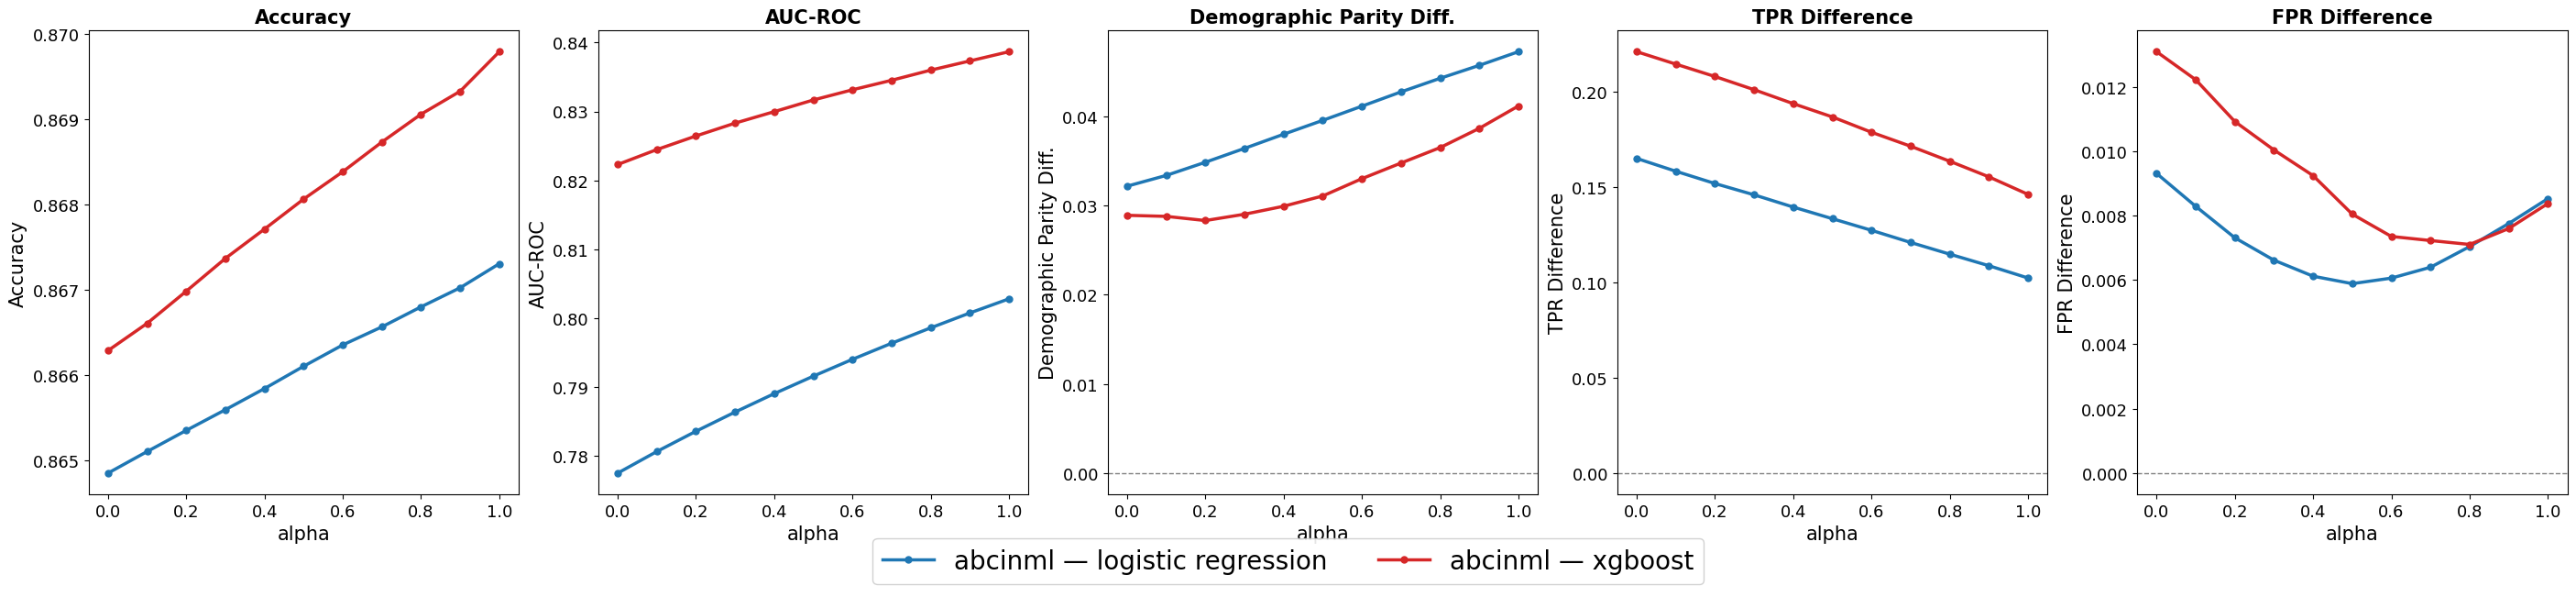

In [6]:
import numpy as np

MODEL_COLORS = {'logistic_regression': '#1f77b4', 'xgboost': '#d62728'}
MODEL_LABELS = {'logistic_regression': 'logistic regression', 'xgboost': 'xgboost'}

monthly_df = assessment_df[assessment_df['batch_type'] == 'monthly']

results_dir = ROOT / 'src' / 'notebooks' / 'figures' / 'seminario'
results_dir.mkdir(parents=True, exist_ok=True)

# ── Chart 1: metric vs alpha, média global sobre os batches ─────────────────
fig, axes = plt.subplots(1, len(_SNAPSHOT_METRICS), figsize=(28, 6.5), layout='constrained')

handles, labels = [], []
for col_idx, (col, label) in enumerate(_SNAPSHOT_METRICS):
    ax = axes[col_idx]

    for model in ['logistic_regression', 'xgboost']:
        sub = monthly_df[monthly_df['model_name'] == model]
        abc = sub[sub['baseline'] == 'abcinml']
        if abc.empty:
            continue
        color = MODEL_COLORS[model]

        curve = abc.groupby('alpha')[col].mean().sort_index()
        line, = ax.plot(curve.index, curve.values, color=color, linewidth=2.5,
                        marker='o', markersize=5, zorder=3)

        if col_idx == 0:
            handles.append(line)
            labels.append(f'abcinml — {MODEL_LABELS[model]}')

    if col in ('sp', 'tpr', 'fpr'):
        ax.axhline(y=0, color='black', linestyle='--', linewidth=1.0, alpha=0.5, zorder=1)

    ax.set_title(label, fontsize=15, fontweight='bold')
    ax.set_ylabel(label, fontsize=15)
    ax.set_xlabel('alpha', fontsize=15)
    ax.set_xticks(np.arange(0, 1.1, 0.2))
    ax.tick_params(axis='x', labelsize=13)
    ax.tick_params(axis='y', labelsize=13)

fig.legend(handles, labels, loc='outside lower center', ncol=len(handles), fontsize=20, framealpha=0.9)

out_path = results_dir / 'alpha_analysis_global.png'
fig.savefig(out_path, dpi=120, bbox_inches='tight')
print(f'Figura salva em {out_path}')

plt.show()

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\seminario\alpha_analysis_by_period_lr.png


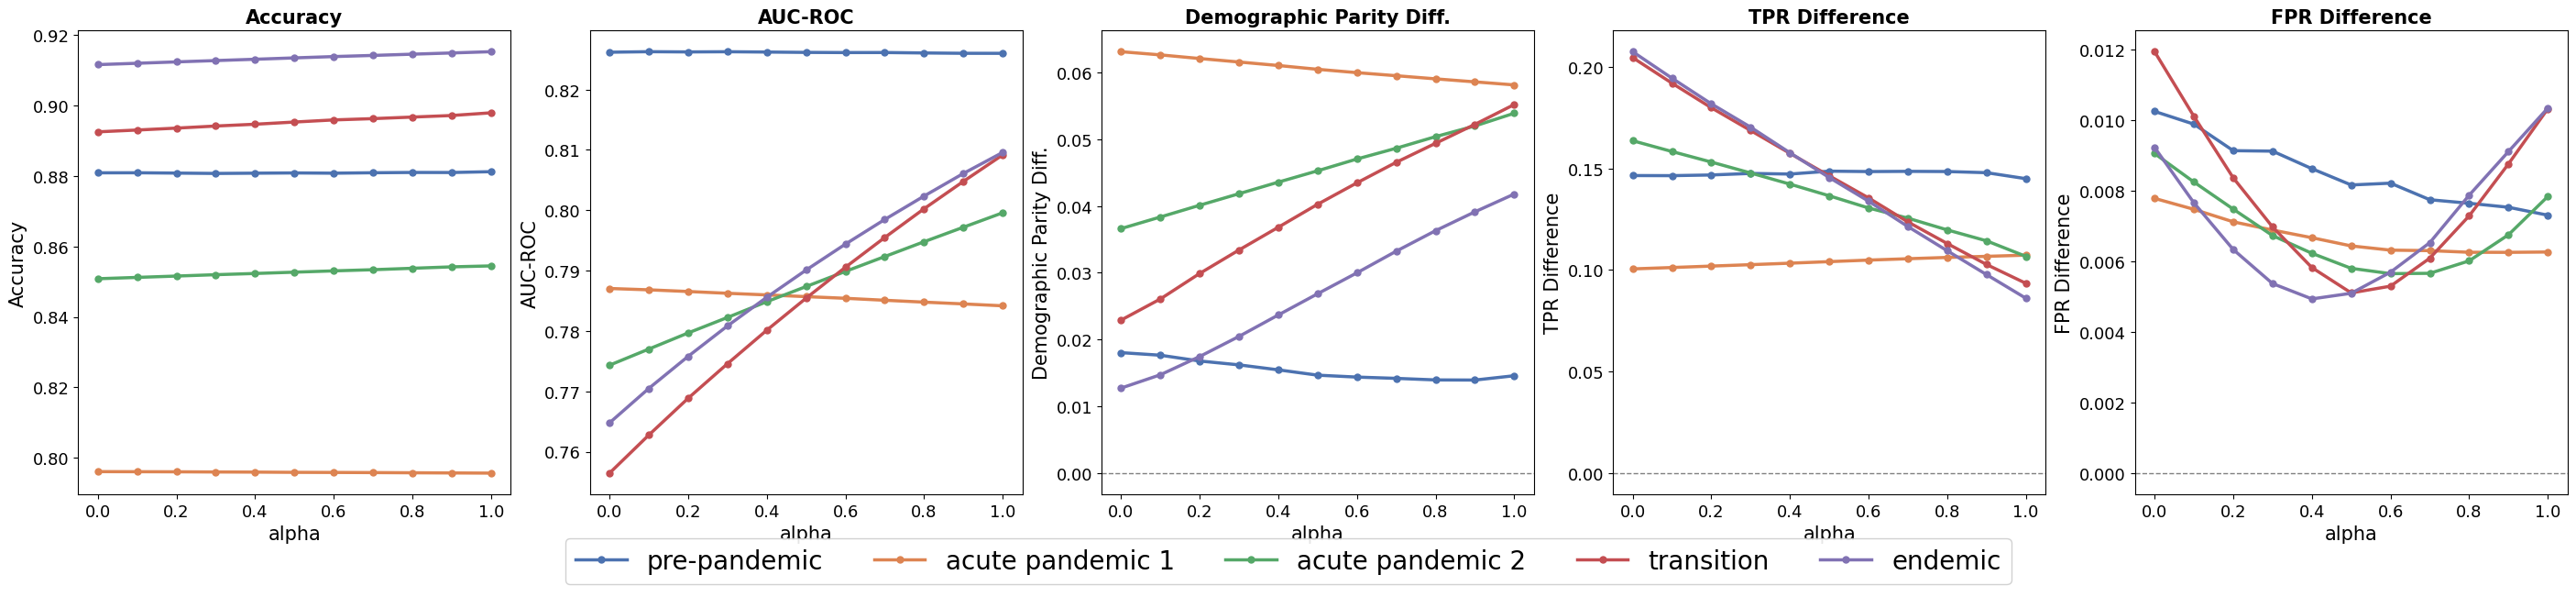

In [7]:
from metrics_utils import _PERIOD_SPANS

# ── Chart 2: metric vs alpha por período epidemiológico (LR, monthly) ───────
lr_abc = monthly_df[
    (monthly_df['model_name'] == 'logistic_regression') & (monthly_df['baseline'] == 'abcinml')
].copy()
lr_abc['batch_dt'] = _batch_to_datetime(lr_abc['batch'].astype(str).tolist(), 'monthly')


def assign_period(dt):
    for start, end, name, color in _PERIOD_SPANS:
        if pd.Timestamp(start) <= dt < pd.Timestamp(end):
            return name
    return None


lr_abc['period'] = lr_abc['batch_dt'].map(assign_period)

fig, axes = plt.subplots(1, len(_SNAPSHOT_METRICS), figsize=(28, 6.5), layout='constrained')

handles, labels = [], []
for col_idx, (col, label) in enumerate(_SNAPSHOT_METRICS):
    ax = axes[col_idx]

    for start, end, name, color in _PERIOD_SPANS:
        sub = lr_abc[lr_abc['period'] == name]
        if sub.empty:
            continue
        curve = sub.groupby('alpha')[col].mean().sort_index()
        line, = ax.plot(curve.index, curve.values, color=color, linewidth=2.5,
                        marker='o', markersize=5, zorder=3)
        if col_idx == 0:
            handles.append(line)
            labels.append(PERIOD_LABELS_EN.get(name, name))

    if col in ('sp', 'tpr', 'fpr'):
        ax.axhline(y=0, color='black', linestyle='--', linewidth=1.0, alpha=0.5, zorder=1)

    ax.set_title(label, fontsize=15, fontweight='bold')
    ax.set_ylabel(label, fontsize=15)
    ax.set_xlabel('alpha', fontsize=15)
    ax.set_xticks(np.arange(0, 1.1, 0.2))
    ax.tick_params(axis='x', labelsize=13)
    ax.tick_params(axis='y', labelsize=13)

fig.legend(handles, labels, loc='outside lower center', ncol=len(handles), fontsize=20, framealpha=0.9)

out_path = results_dir / 'alpha_analysis_by_period_lr.png'
fig.savefig(out_path, dpi=120, bbox_inches='tight')
print(f'Figura salva em {out_path}')

plt.show()

### Taxas absolutas por grupo sensível — média por baseline

Réplica da lógica de `metrics_utils._generate_absolute_rates_chart` sobre os resultados agregados (`absolute_results_df.csv`), filtrando **logistic regression + monthly** e agregando as taxas pela **média por `(baseline, batch)`** (colapsando alphas, técnicas e janelas). Grade 4×2: uma fileira por baseline, colunas TPR e FPR, com média móvel de 10 batches e as linhas dos grupos S0 (privilegiado, idade < 65) e S1 (sensível, idade ≥ 65). Rótulos em inglês.

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\seminario\absolute_rates_by_group_lr.png


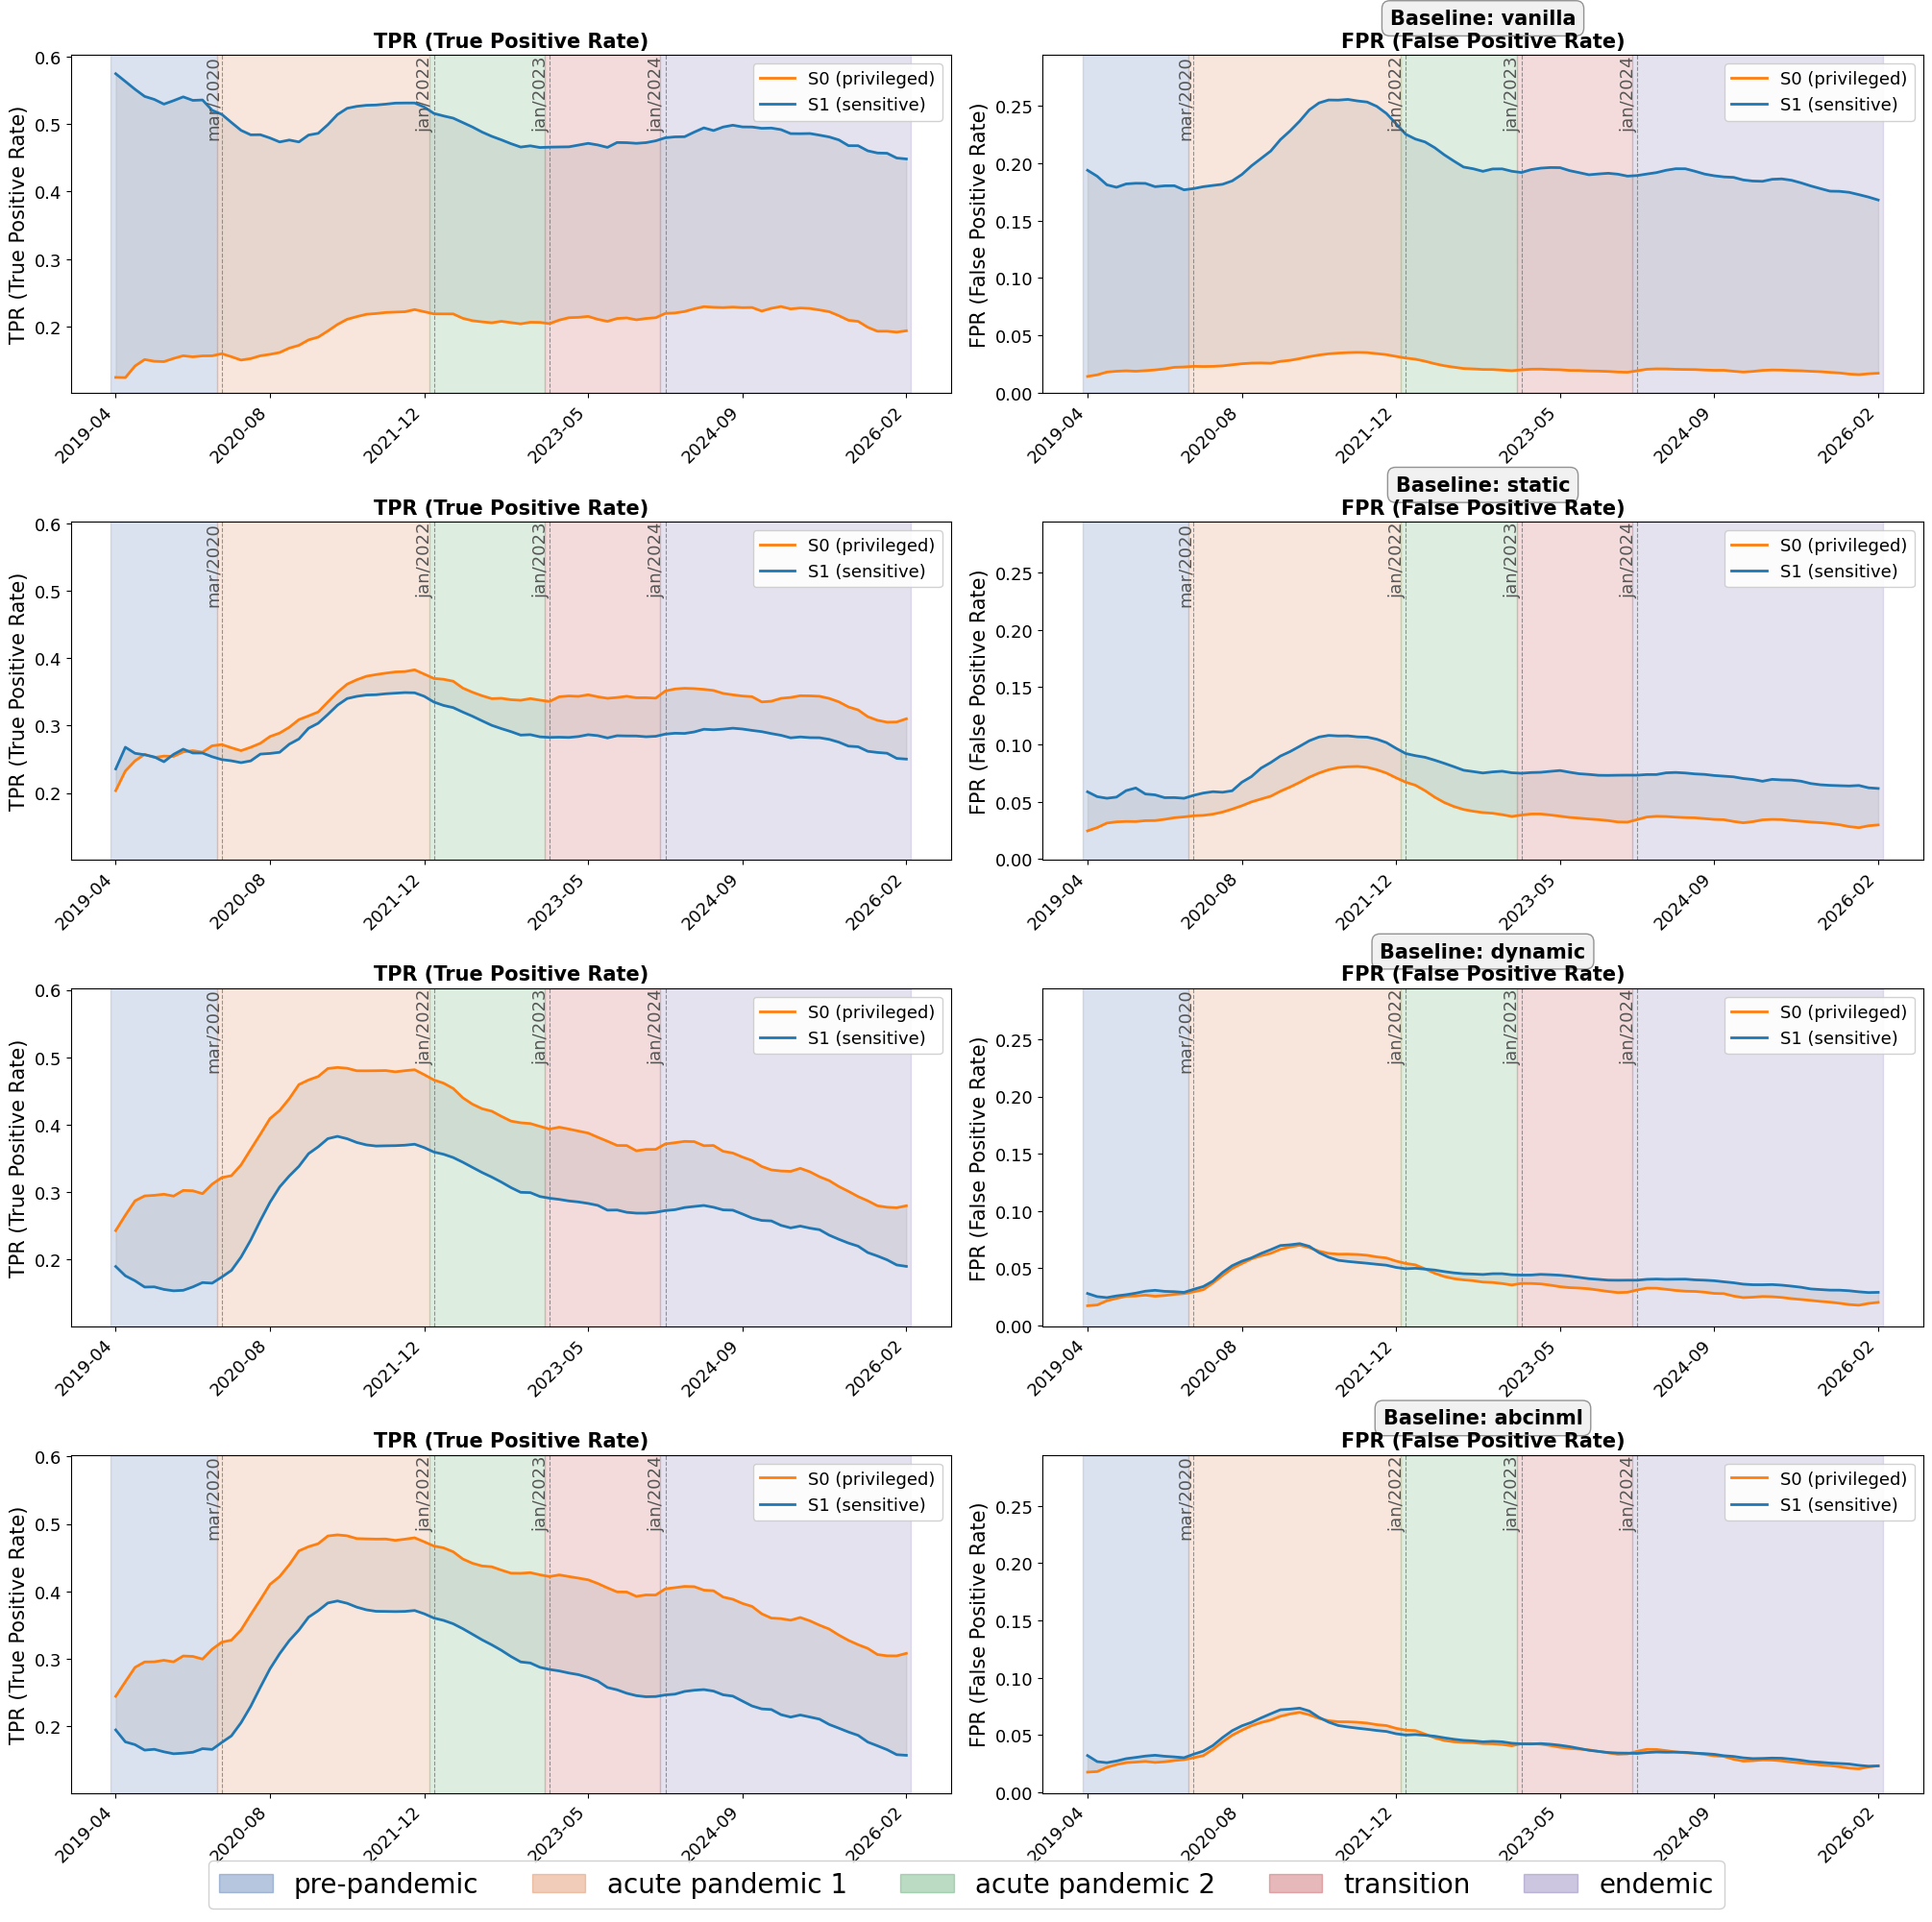

In [8]:
# Carrega e filtra as taxas absolutas: LR + monthly
absolute_df = pd.read_csv(ROOT / 'src' / 'results' / 'all' / 'absolute_results_df.csv')
abs_lr = absolute_df[
    (absolute_df['model_name'] == 'logistic_regression')
    & (absolute_df['batch_type'] == 'monthly')
].copy()

_MA_WINDOW = 10  # padrão do pipeline para monthly
_S0_COLOR = '#ff7f0e'
_S1_COLOR = '#1f77b4'

rate_cols = ['tpr_S0', 'fpr_S0', 'tpr_S1', 'fpr_S1']
abs_lr['batch_dt'] = _batch_to_datetime(abs_lr['batch'].astype(str).tolist(), 'monthly')

# Média por (baseline, batch): colapsa alphas, técnicas de forecasting e janelas
abs_mean = abs_lr.groupby(['baseline', 'batch', 'batch_dt'], as_index=False)[rate_cols].mean()

present_baselines = [b for b in _BASELINE_ORDER if b in abs_mean['baseline'].unique()]
n_rows = len(present_baselines)
all_batch_labels = sorted(abs_mean['batch'].astype(str).unique())

tpr_values = pd.concat([abs_mean['tpr_S0'], abs_mean['tpr_S1']])
tpr_pad = (tpr_values.max() - tpr_values.min()) * 0.05
tpr_ylim = (tpr_values.min() - tpr_pad, tpr_values.max() + tpr_pad)

fpr_values = pd.concat([abs_mean['fpr_S0'], abs_mean['fpr_S1']])
fpr_pad = (fpr_values.max() - fpr_values.min()) * 0.05
fpr_ylim = (fpr_values.min() - fpr_pad, fpr_values.max() + fpr_pad)

_RATE_PAIRS = [
    ('tpr_S0', 'tpr_S1', 'TPR (True Positive Rate)', tpr_ylim),
    ('fpr_S0', 'fpr_S1', 'FPR (False Positive Rate)', fpr_ylim),
]

fig, axes = plt.subplots(n_rows, 2, figsize=(20, 5 * n_rows), squeeze=False, layout='constrained')

period_handles = []
for row, bt in enumerate(present_baselines):
    sub = abs_mean[abs_mean['baseline'] == bt].sort_values('batch_dt').reset_index(drop=True)
    x_str = sub['batch'].astype(str).tolist()
    x_idx = [all_batch_labels.index(b) for b in x_str if b in all_batch_labels]

    for col_idx, (col_s0, col_s1, col_label, ylim) in enumerate(_RATE_PAIRS):
        ax = axes[row][col_idx]

        handles = _add_period_spans(ax, all_batch_labels, 'monthly')
        if not period_handles:
            period_handles = handles

        ma_s0 = sub[col_s0].rolling(window=_MA_WINDOW, min_periods=1).mean().values
        ma_s1 = sub[col_s1].rolling(window=_MA_WINDOW, min_periods=1).mean().values

        line_s0, = ax.plot(x_idx, ma_s0, color=_S0_COLOR, linewidth=2.0, label='S0 (privileged)')
        line_s1, = ax.plot(x_idx, ma_s1, color=_S1_COLOR, linewidth=2.0, label='S1 (sensitive)')
        ax.fill_between(x_idx, ma_s0, ma_s1, alpha=0.15, color='gray')

        ax.set_title(col_label, fontsize=15, fontweight='bold')
        ax.set_ylabel(col_label, fontsize=15)
        ax.set_ylim(ylim)
        # Legenda interna só com as linhas dos grupos (os períodos ficam na legenda geral)
        ax.legend(handles=[line_s0, line_s1], fontsize=13, framealpha=0.9)
        _apply_bin_xticks(ax, all_batch_labels)
        ax.tick_params(axis='x', labelsize=13)
        ax.tick_params(axis='y', labelsize=13)

    # Rótulo do baseline acima da fileira (coluna direita, como no pipeline)
    axes[row][1].annotate(
        f'Baseline: {bt}',
        xy=(0.5, 1.08),
        xycoords='axes fraction',
        ha='center',
        va='bottom',
        fontsize=15,
        fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='#f0f0f0', edgecolor='#888888', alpha=0.9),
    )


# Ajustes pós-plot (identidade do seminário): alpha das faixas e fonte dos
# rótulos das vlines — só os textos de data (contêm '/'), preservando as annotations
for ax in fig.axes:
    for patch in ax.patches:
        patch.set_alpha(0.20)
    for text in ax.texts:
        if '/' in text.get_text():
            text.set_fontsize(13)

period_labels = [PERIOD_LABELS_EN.get(h.get_label(), h.get_label()) for h in period_handles]
leg = fig.legend(
    period_handles, period_labels,
    loc='outside lower center', ncol=len(period_handles), fontsize=20, framealpha=0.9,
)
for legend_patch in leg.get_patches():
    legend_patch.set_alpha(0.4)

out_path = results_dir / 'absolute_rates_by_group_lr.png'
fig.savefig(out_path, dpi=120, bbox_inches='tight')
print(f'Figura salva em {out_path}')

plt.show()

## Versões XGBoost

Os mesmos gráficos gerados acima, agora para o modelo **xgboost** (o gráfico *Metric vs Alpha global* já inclui as duas linhas de modelo, então não é repetido):

1. Comparação dos 4 baselines — monthly e weekly
2. Metric vs Alpha por período epidemiológico
3. Taxas absolutas TPR/FPR por grupo sensível

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\seminario\comparacao_baselines_xgboost.png


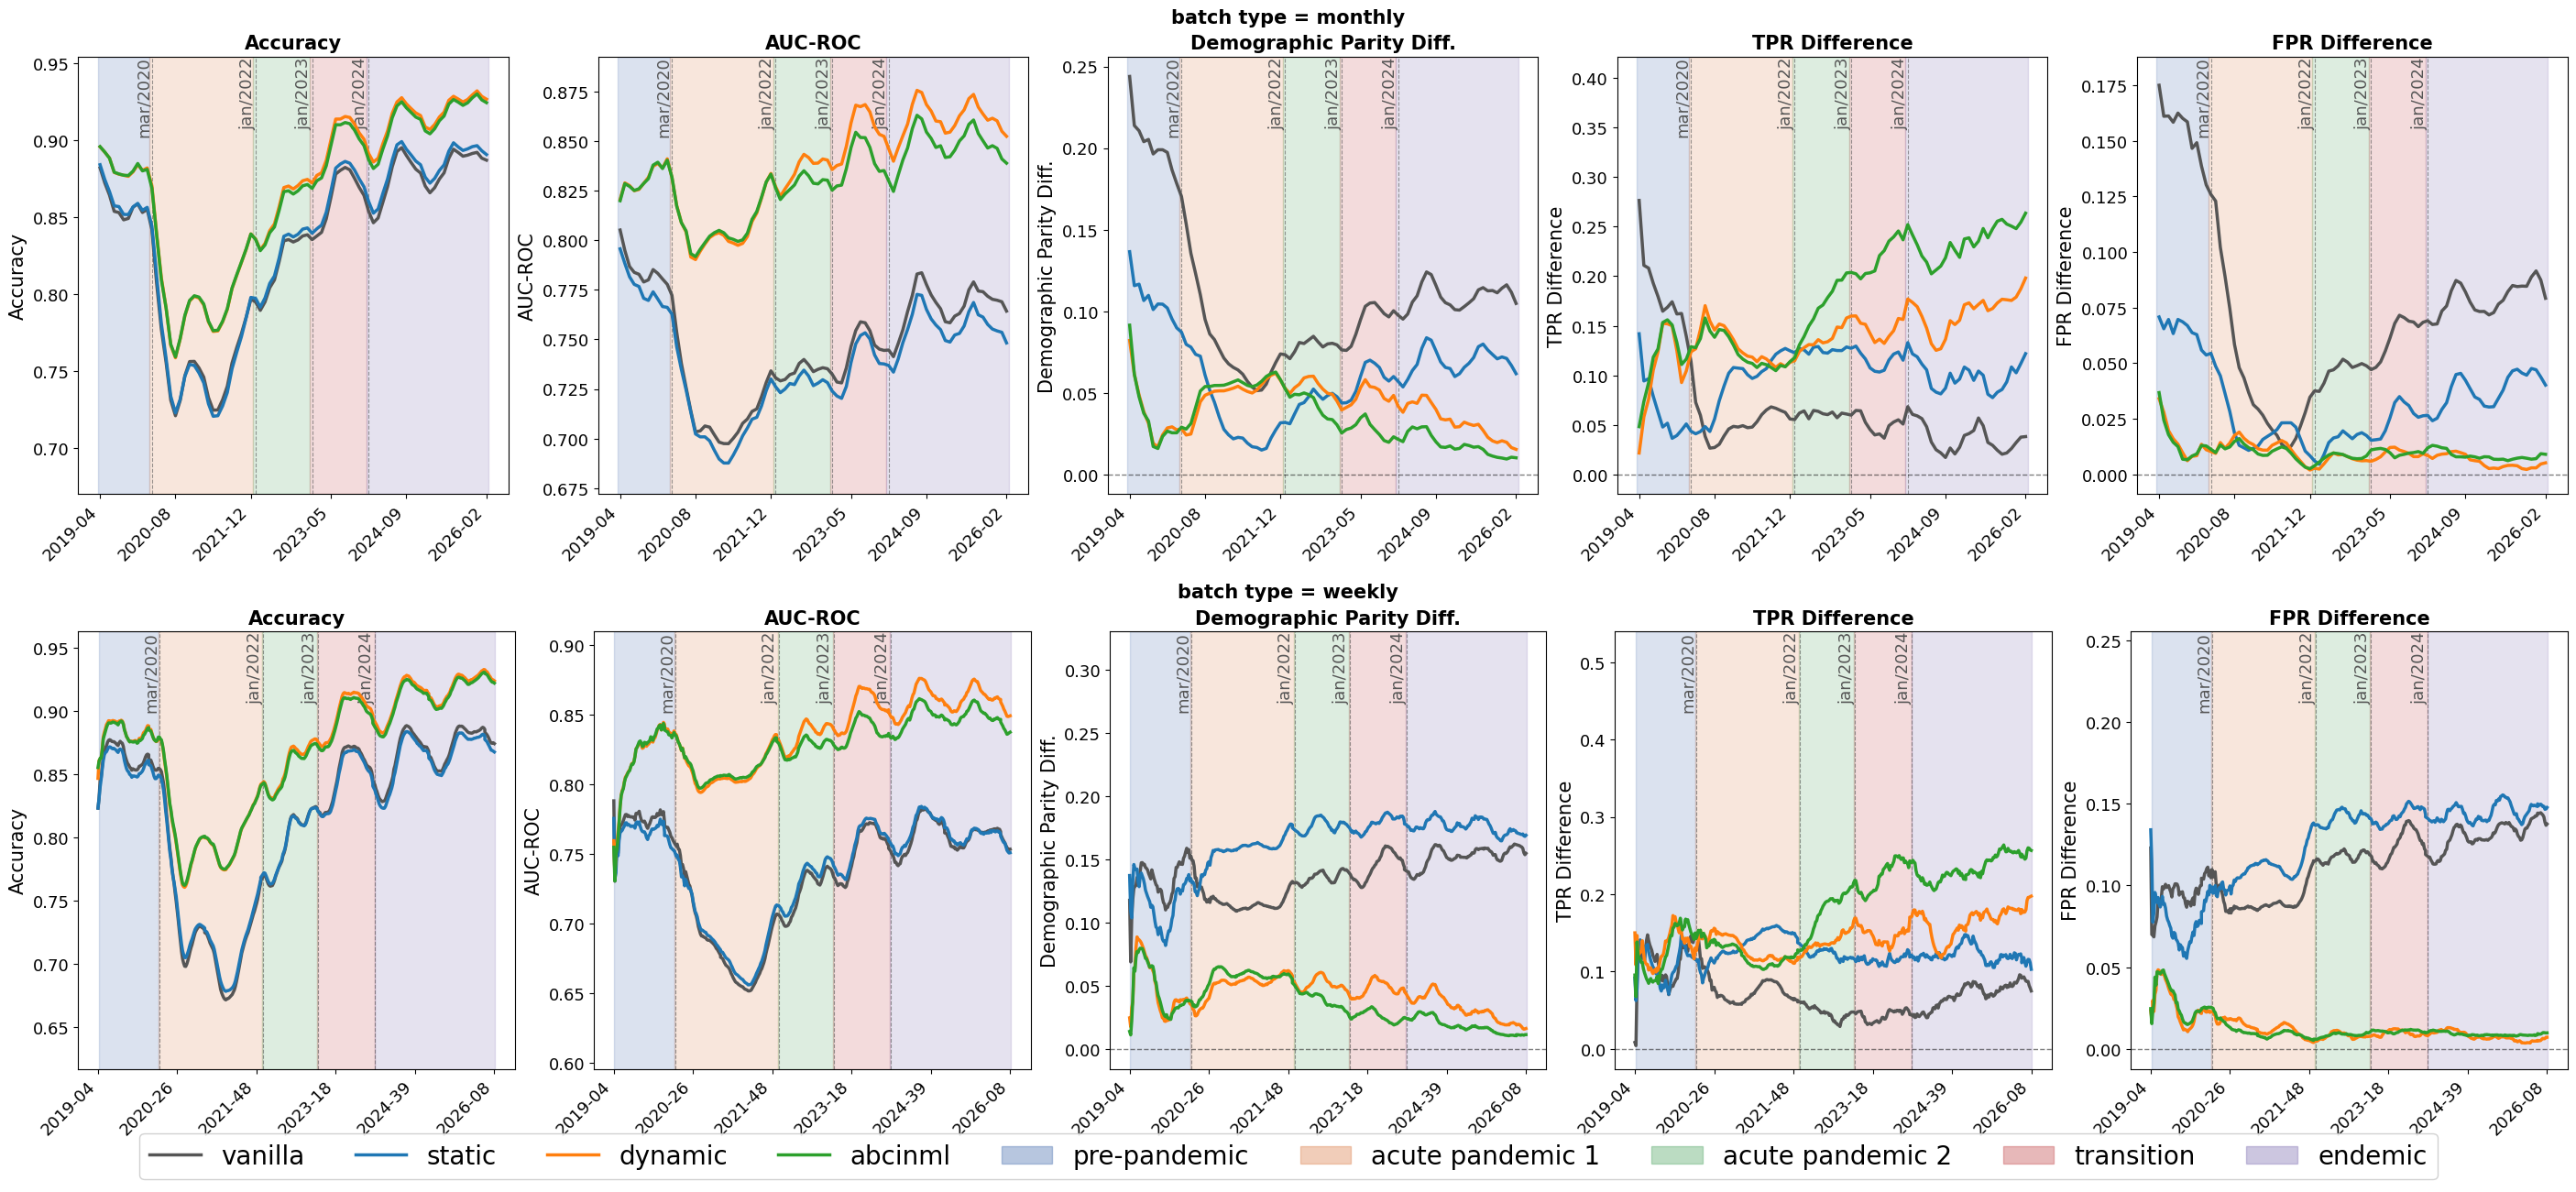

In [9]:
# ── XGBoost: comparação dos 4 baselines (monthly + weekly) ──────────────────
xgb_df = assessment_df[assessment_df['model_name'] == 'xgboost']
xgb_monthly_df = xgb_df[xgb_df['batch_type'] == 'monthly'].copy()
xgb_weekly_df = xgb_df[xgb_df['batch_type'] == 'weekly'].copy()

fig = plt.figure(figsize=(28, 13), layout='constrained')
subfigs = fig.subfigures(2, 1)

rows = [
    ('monthly', xgb_monthly_df, 5),
    ('weekly', xgb_weekly_df, 20),
]

baseline_handles, period_handles = [], []
for subfig, (batch_type, df_row, ma_window) in zip(subfigs, rows):
    axes = subfig.subplots(1, len(_SNAPSHOT_METRICS))
    subfig.suptitle(f'batch type = {batch_type}', fontsize=15, fontweight='bold')
    bh, ph = plot_baselines_row(axes, df_row, batch_type, ma_window)
    if not baseline_handles:
        baseline_handles, period_handles = bh, ph


# Ajustes pós-plot: alpha das faixas e fonte dos rótulos das vlines
for ax in fig.axes:
    for patch in ax.patches:
        patch.set_alpha(0.20)
    for text in ax.texts:
        text.set_fontsize(13)

all_handles = baseline_handles + period_handles
legend_labels = [PERIOD_LABELS_EN.get(h.get_label(), h.get_label()) for h in all_handles]
leg = fig.legend(
    all_handles, legend_labels,
    loc='outside lower center', ncol=len(all_handles), fontsize=20, framealpha=0.9,
)
for legend_patch in leg.get_patches():
    legend_patch.set_alpha(0.4)

fig_path = results_dir / 'comparacao_baselines_xgboost.png'
fig.savefig(fig_path, dpi=120, bbox_inches='tight')
print(f'Figura salva em {fig_path}')

plt.show()

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\seminario\alpha_analysis_by_period_xgboost.png


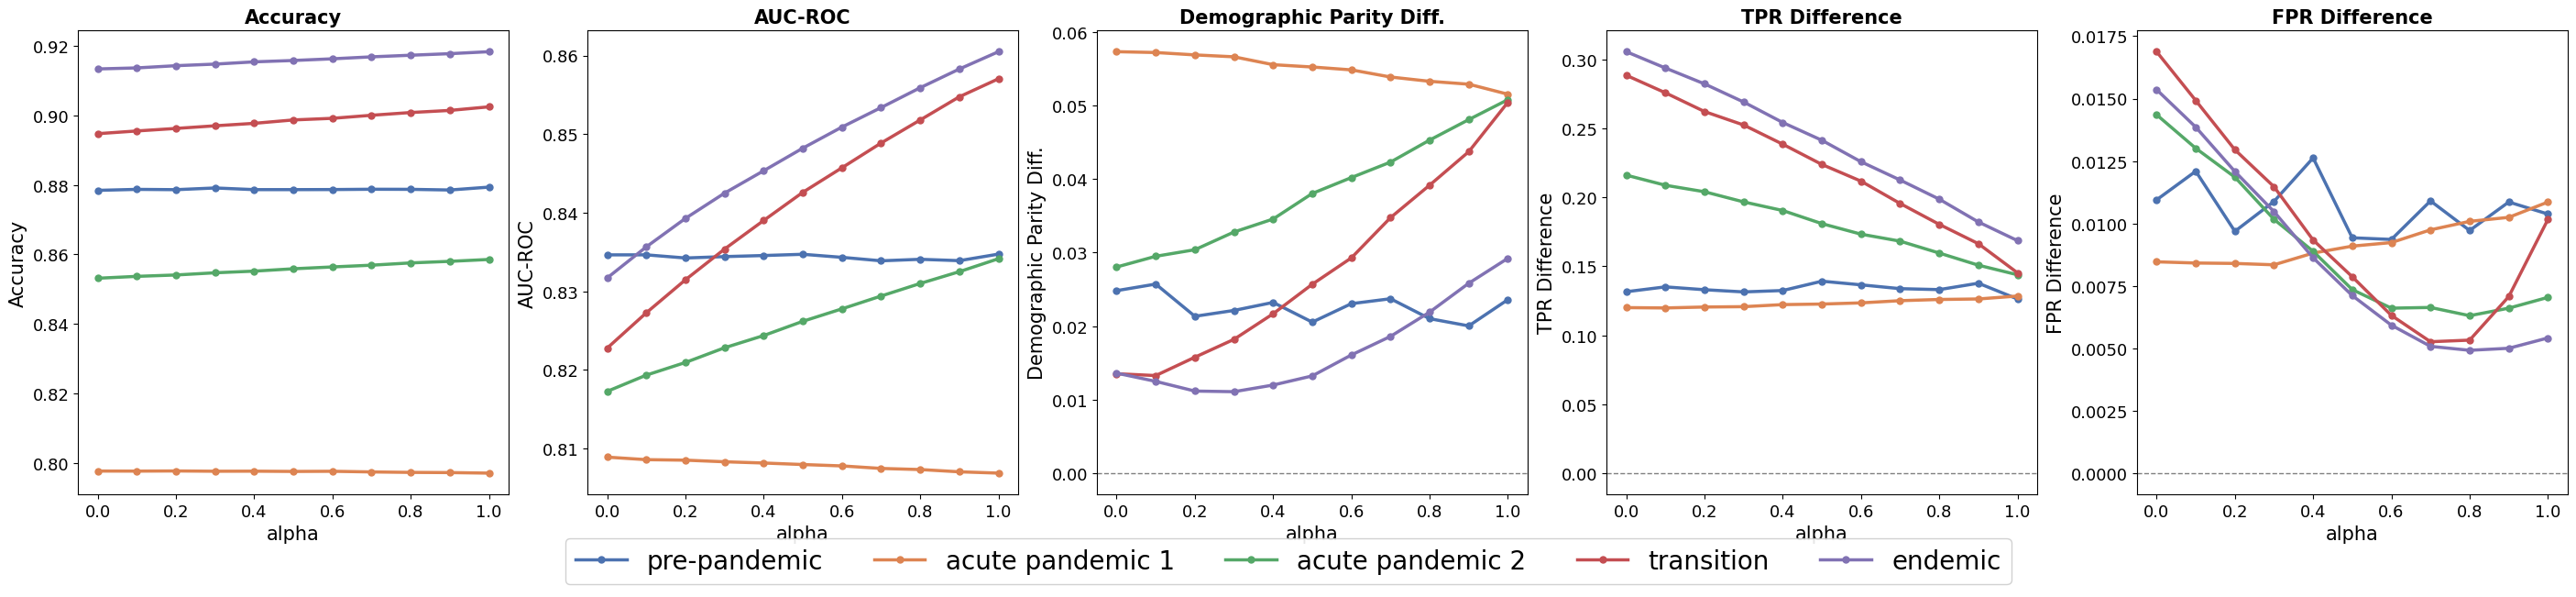

In [10]:
# ── XGBoost: metric vs alpha por período epidemiológico (monthly) ───────────
xgb_abc = monthly_df[
    (monthly_df['model_name'] == 'xgboost') & (monthly_df['baseline'] == 'abcinml')
].copy()
xgb_abc['batch_dt'] = _batch_to_datetime(xgb_abc['batch'].astype(str).tolist(), 'monthly')
xgb_abc['period'] = xgb_abc['batch_dt'].map(assign_period)

fig, axes = plt.subplots(1, len(_SNAPSHOT_METRICS), figsize=(28, 6.5), layout='constrained')

handles, labels = [], []
for col_idx, (col, label) in enumerate(_SNAPSHOT_METRICS):
    ax = axes[col_idx]

    for start, end, name, color in _PERIOD_SPANS:
        sub = xgb_abc[xgb_abc['period'] == name]
        if sub.empty:
            continue
        curve = sub.groupby('alpha')[col].mean().sort_index()
        line, = ax.plot(curve.index, curve.values, color=color, linewidth=2.5,
                        marker='o', markersize=5, zorder=3)
        if col_idx == 0:
            handles.append(line)
            labels.append(PERIOD_LABELS_EN.get(name, name))

    if col in ('sp', 'tpr', 'fpr'):
        ax.axhline(y=0, color='black', linestyle='--', linewidth=1.0, alpha=0.5, zorder=1)

    ax.set_title(label, fontsize=15, fontweight='bold')
    ax.set_ylabel(label, fontsize=15)
    ax.set_xlabel('alpha', fontsize=15)
    ax.set_xticks(np.arange(0, 1.1, 0.2))
    ax.tick_params(axis='x', labelsize=13)
    ax.tick_params(axis='y', labelsize=13)

fig.legend(handles, labels, loc='outside lower center', ncol=len(handles), fontsize=20, framealpha=0.9)

out_path = results_dir / 'alpha_analysis_by_period_xgboost.png'
fig.savefig(out_path, dpi=120, bbox_inches='tight')
print(f'Figura salva em {out_path}')

plt.show()

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\seminario\absolute_rates_by_group_xgboost.png


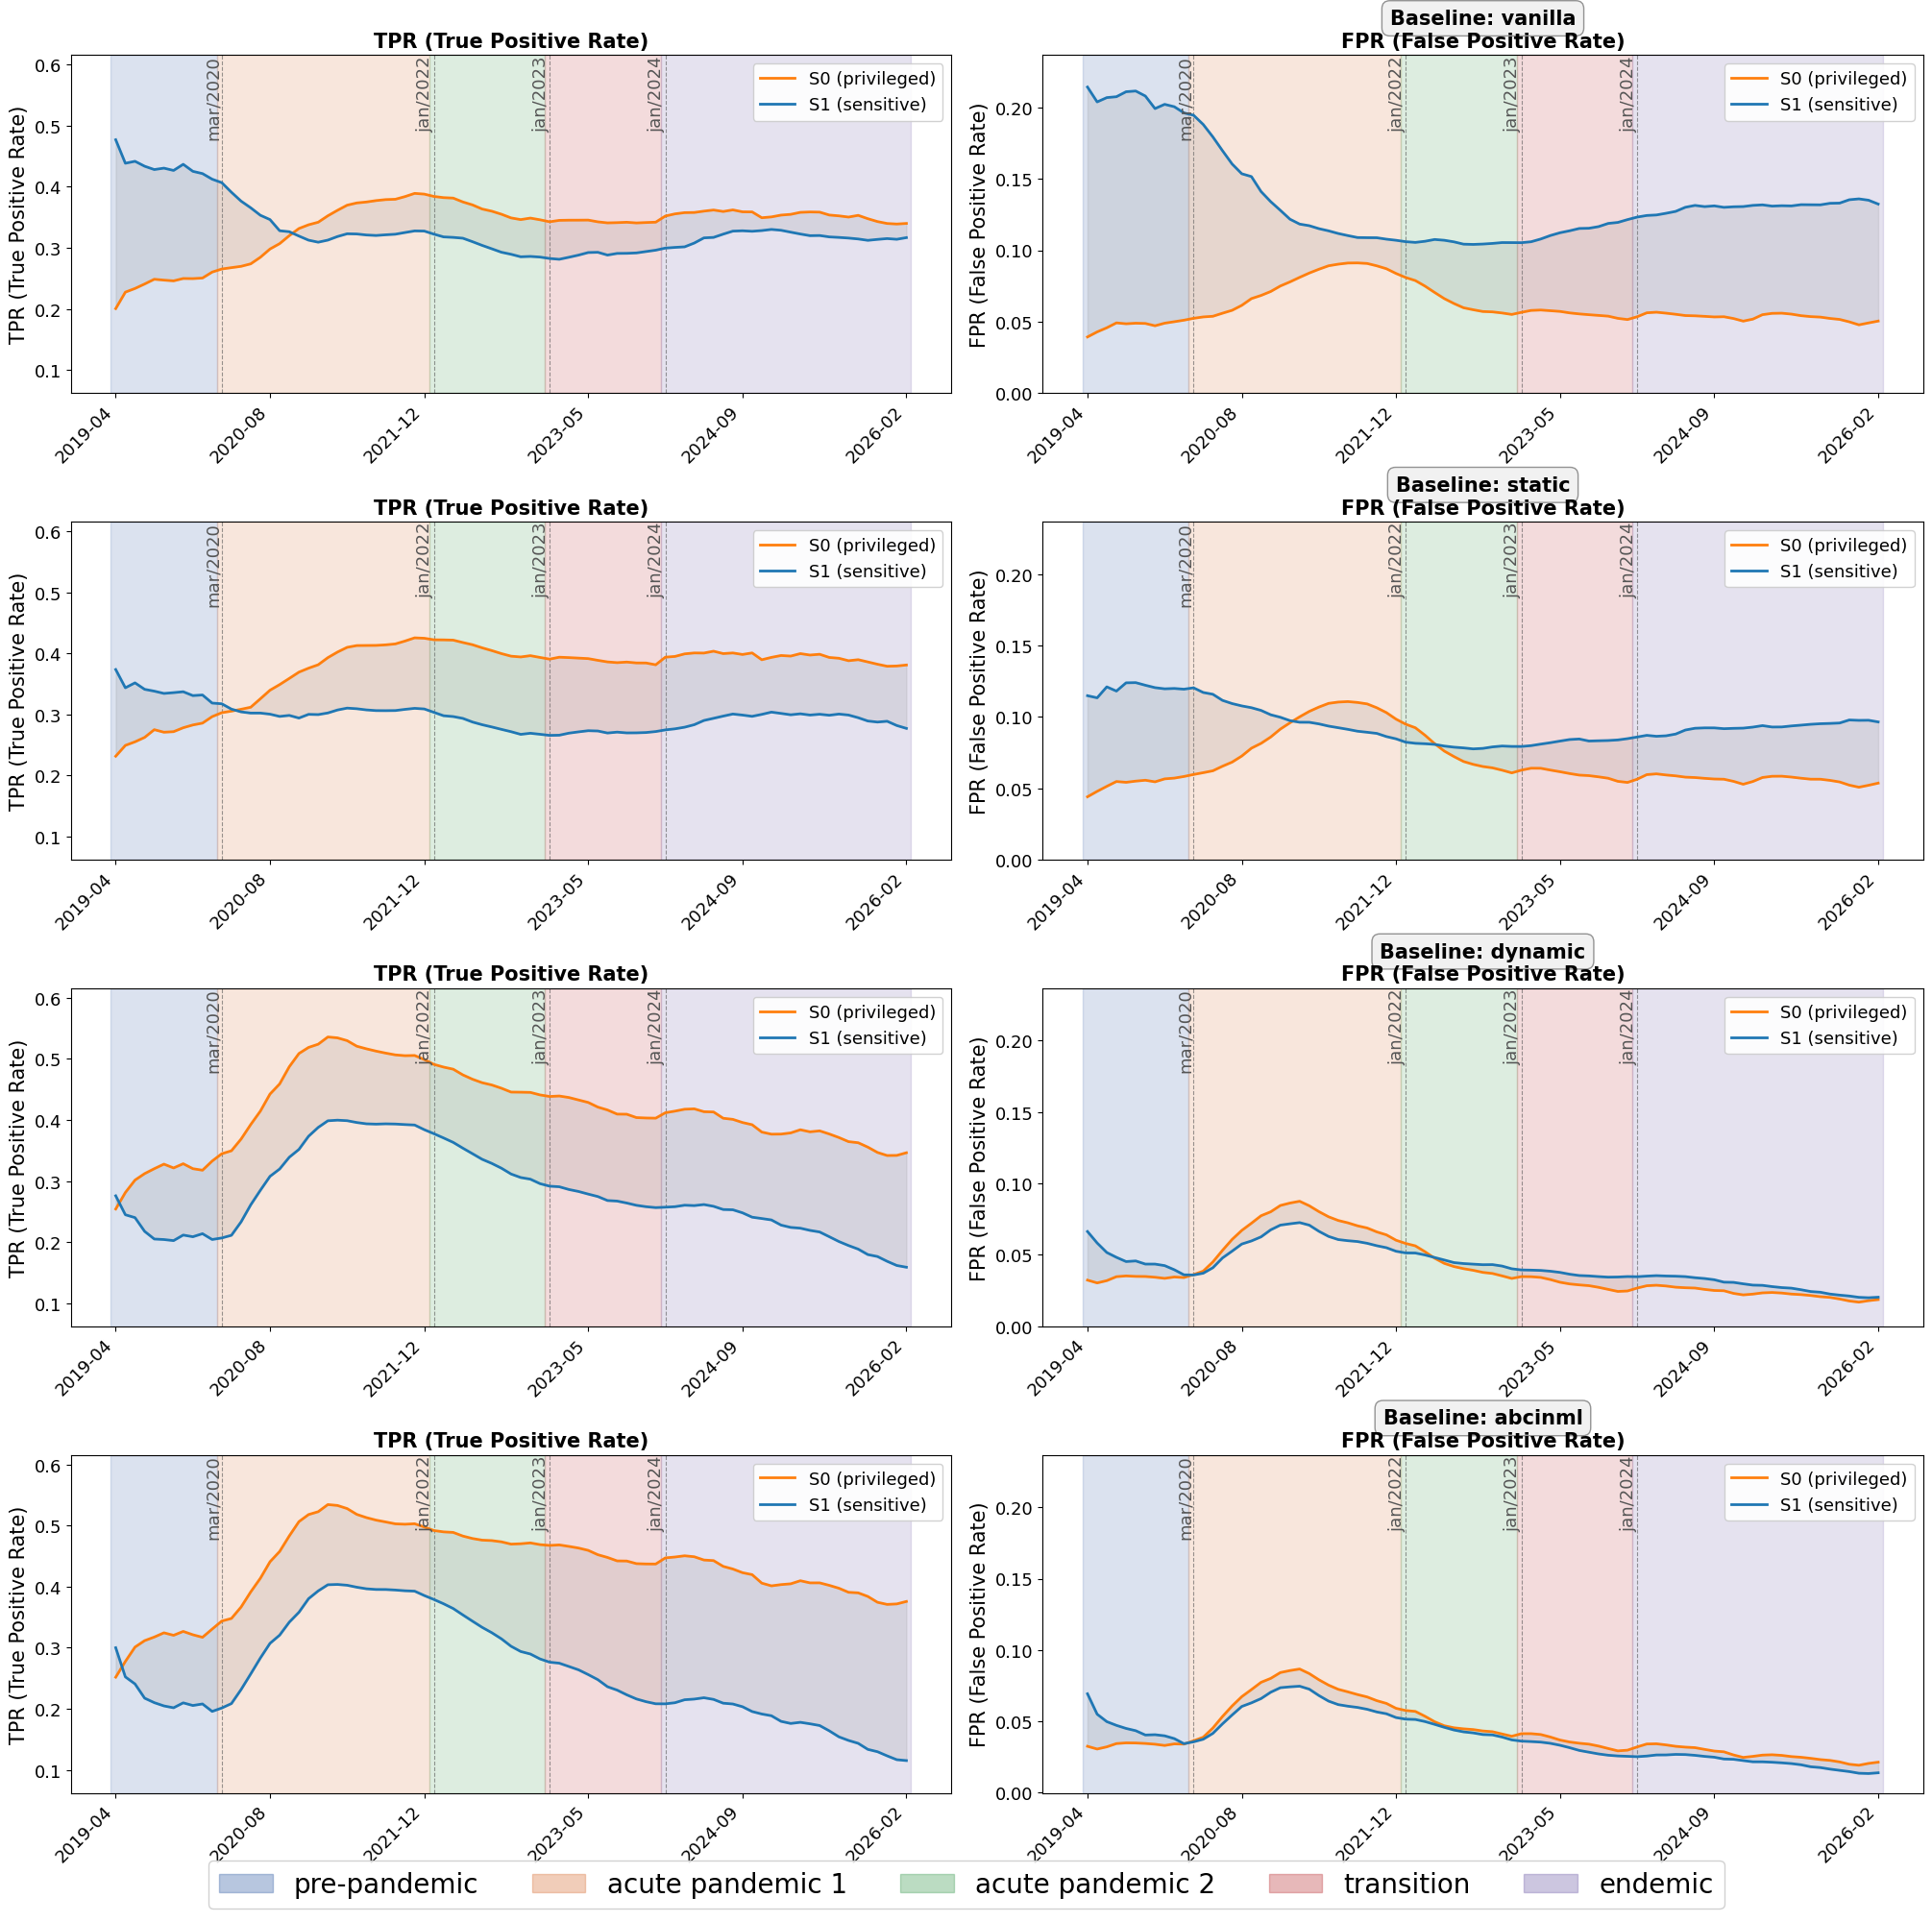

In [11]:
# ── XGBoost: taxas absolutas TPR/FPR por grupo sensível (monthly) ───────────
abs_xgb = absolute_df[
    (absolute_df['model_name'] == 'xgboost')
    & (absolute_df['batch_type'] == 'monthly')
].copy()

abs_xgb['batch_dt'] = _batch_to_datetime(abs_xgb['batch'].astype(str).tolist(), 'monthly')
abs_mean = abs_xgb.groupby(['baseline', 'batch', 'batch_dt'], as_index=False)[rate_cols].mean()

present_baselines = [b for b in _BASELINE_ORDER if b in abs_mean['baseline'].unique()]
n_rows = len(present_baselines)
all_batch_labels = sorted(abs_mean['batch'].astype(str).unique())

tpr_values = pd.concat([abs_mean['tpr_S0'], abs_mean['tpr_S1']])
tpr_pad = (tpr_values.max() - tpr_values.min()) * 0.05
tpr_ylim = (tpr_values.min() - tpr_pad, tpr_values.max() + tpr_pad)

fpr_values = pd.concat([abs_mean['fpr_S0'], abs_mean['fpr_S1']])
fpr_pad = (fpr_values.max() - fpr_values.min()) * 0.05
fpr_ylim = (fpr_values.min() - fpr_pad, fpr_values.max() + fpr_pad)

_RATE_PAIRS = [
    ('tpr_S0', 'tpr_S1', 'TPR (True Positive Rate)', tpr_ylim),
    ('fpr_S0', 'fpr_S1', 'FPR (False Positive Rate)', fpr_ylim),
]

fig, axes = plt.subplots(n_rows, 2, figsize=(20, 5 * n_rows), squeeze=False, layout='constrained')

period_handles = []
for row, bt in enumerate(present_baselines):
    sub = abs_mean[abs_mean['baseline'] == bt].sort_values('batch_dt').reset_index(drop=True)
    x_str = sub['batch'].astype(str).tolist()
    x_idx = [all_batch_labels.index(b) for b in x_str if b in all_batch_labels]

    for col_idx, (col_s0, col_s1, col_label, ylim) in enumerate(_RATE_PAIRS):
        ax = axes[row][col_idx]

        handles = _add_period_spans(ax, all_batch_labels, 'monthly')
        if not period_handles:
            period_handles = handles

        ma_s0 = sub[col_s0].rolling(window=_MA_WINDOW, min_periods=1).mean().values
        ma_s1 = sub[col_s1].rolling(window=_MA_WINDOW, min_periods=1).mean().values

        line_s0, = ax.plot(x_idx, ma_s0, color=_S0_COLOR, linewidth=2.0, label='S0 (privileged)')
        line_s1, = ax.plot(x_idx, ma_s1, color=_S1_COLOR, linewidth=2.0, label='S1 (sensitive)')
        ax.fill_between(x_idx, ma_s0, ma_s1, alpha=0.15, color='gray')

        ax.set_title(col_label, fontsize=15, fontweight='bold')
        ax.set_ylabel(col_label, fontsize=15)
        ax.set_ylim(ylim)
        ax.legend(handles=[line_s0, line_s1], fontsize=13, framealpha=0.9)
        _apply_bin_xticks(ax, all_batch_labels)
        ax.tick_params(axis='x', labelsize=13)
        ax.tick_params(axis='y', labelsize=13)

    axes[row][1].annotate(
        f'Baseline: {bt}',
        xy=(0.5, 1.08),
        xycoords='axes fraction',
        ha='center',
        va='bottom',
        fontsize=15,
        fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='#f0f0f0', edgecolor='#888888', alpha=0.9),
    )


for ax in fig.axes:
    for patch in ax.patches:
        patch.set_alpha(0.20)
    for text in ax.texts:
        if '/' in text.get_text():
            text.set_fontsize(13)

period_labels = [PERIOD_LABELS_EN.get(h.get_label(), h.get_label()) for h in period_handles]
leg = fig.legend(
    period_handles, period_labels,
    loc='outside lower center', ncol=len(period_handles), fontsize=20, framealpha=0.9,
)
for legend_patch in leg.get_patches():
    legend_patch.set_alpha(0.4)

out_path = results_dir / 'absolute_rates_by_group_xgboost.png'
fig.savefig(out_path, dpi=120, bbox_inches='tight')
print(f'Figura salva em {out_path}')

plt.show()

## Tabela pivot — TPR/FPR médios por baseline e grupo

Alternativa compacta ao gráfico de taxas absolutas (grande demais para artigo). Para cada modelo, uma tabela pivot com o TPR e o FPR **médios** (em %) por baseline, decompostos nos grupos S0 (privileged, idade < 65) e S1 (sensitive, idade ≥ 65). Segue a mesma agregação dos gráficos: média por `(baseline, batch)` sobre os batches **monthly** e depois média sobre os batches. Salvas como imagem em `src/notebooks/figures/seminario/`.

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\seminario\absolute_rates_pivot_lr.png


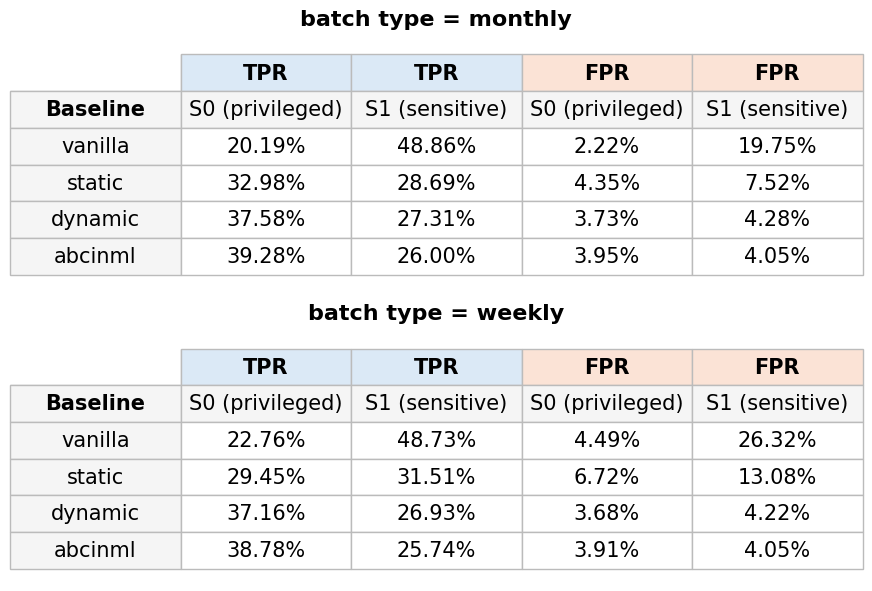

Metric               TPR                            FPR               
Group    S0 (privileged) S1 (sensitive) S0 (privileged) S1 (sensitive)
Baseline                                                              
vanilla            20.19          48.86            2.22          19.75
static             32.98          28.69            4.35           7.52
dynamic            37.58          27.31            3.73           4.28
abcinml            39.28          26.00            3.95           4.05

In [12]:
def absolute_rates_pivot(model_name, batch_type, as_percent=True):
    """Pivot: linhas = baseline, colunas = (TPR/FPR) × (S0/S1), média sobre os batches."""
    sub = absolute_df[
        (absolute_df['model_name'] == model_name)
        & (absolute_df['batch_type'] == batch_type)
    ]
    # média por (baseline, batch) e depois média sobre os batches
    per_batch = sub.groupby(['baseline', 'batch'], as_index=False)[rate_cols].mean()
    agg = (
        per_batch.groupby('baseline')[rate_cols].mean()
        .reindex([b for b in _BASELINE_ORDER if b in per_batch['baseline'].unique()])
    )
    piv = pd.DataFrame({
        ('TPR', 'S0 (privileged)'): agg['tpr_S0'],
        ('TPR', 'S1 (sensitive)'): agg['tpr_S1'],
        ('FPR', 'S0 (privileged)'): agg['fpr_S0'],
        ('FPR', 'S1 (sensitive)'): agg['fpr_S1'],
    })
    piv.columns = pd.MultiIndex.from_tuples(piv.columns, names=['Metric', 'Group'])
    piv.index.name = 'Baseline'
    if as_percent:
        piv = piv * 100
    return piv.round(2)


def _draw_pivot_table(ax, piv, subtitle):
    """Desenha uma pivot (colunas MultiIndex 2 níveis) como tabela num eixo, com subtítulo."""
    ax.axis('off')
    ax.set_title(subtitle, fontsize=16, fontweight='bold', pad=12)

    header_metric = [''] + [m for m, _ in piv.columns]           # linha 1: TPR/FPR
    header_group = ['Baseline'] + [g for _, g in piv.columns]    # linha 2: Baseline / S0 / S1
    body = [[idx] + [f'{v:.2f}%' for v in row] for idx, row in zip(piv.index, piv.values)]
    table_data = [header_metric, header_group] + body

    tbl = ax.table(cellText=table_data, cellLoc='center', loc='center')
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(15)
    tbl.scale(1, 2.2)

    metric_fill = {'TPR': '#dbe9f6', 'FPR': '#fbe3d6'}
    light_gray = '#f5f5f5'
    for (r, c), cell in tbl.get_celld().items():
        cell.set_edgecolor('#bbbbbb')
        if r == 0:  # linha de métrica: TPR/FPR em bold
            txt = cell.get_text().get_text()
            cell.set_facecolor(metric_fill.get(txt, 'white'))
            if txt:
                cell.get_text().set_fontweight('bold')
            if c == 0:
                cell.set_facecolor('white')
                cell.visible_edges = 'BR'
        elif r == 1:  # cabeçalho: só 'Baseline' em bold; grupos normais, fundo cinza leve
            cell.set_facecolor(light_gray)
            if c == 0:
                cell.get_text().set_fontweight('bold')
        elif c == 0:  # coluna de baseline (valores): fundo cinza leve, sem bold
            cell.set_facecolor(light_gray)


def save_pivot_image(model_name, out_path):
    """Uma imagem com duas pivots empilhadas: monthly (cima) e weekly (baixo)."""
    piv_monthly = absolute_rates_pivot(model_name, 'monthly')
    piv_weekly = absolute_rates_pivot(model_name, 'weekly')
    n_rows, n_cols = piv_monthly.shape
    width = 1.9 * (n_cols + 1) + 1.5
    fig, axes = plt.subplots(2, 1, figsize=(width, 2 * (0.5 * (n_rows + 2) + 0.5)))

    _draw_pivot_table(axes[0], piv_monthly, 'batch type = monthly')
    _draw_pivot_table(axes[1], piv_weekly, 'batch type = weekly')

    fig.savefig(out_path, dpi=120, bbox_inches='tight', pad_inches=0.05)
    print(f'Figura salva em {out_path}')


save_pivot_image('logistic_regression', results_dir / 'absolute_rates_pivot_lr.png')
plt.show()
absolute_rates_pivot('logistic_regression', 'monthly')

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\seminario\absolute_rates_pivot_xgboost.png


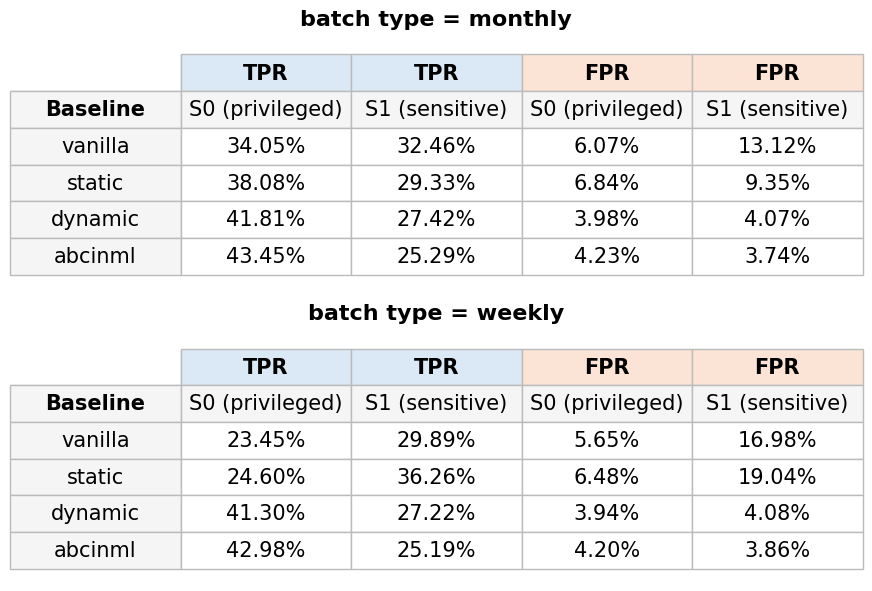

Metric               TPR                            FPR               
Group    S0 (privileged) S1 (sensitive) S0 (privileged) S1 (sensitive)
Baseline                                                              
vanilla            23.45          29.89            5.65          16.98
static             24.60          36.26            6.48          19.04
dynamic            41.30          27.22            3.94           4.08
abcinml            42.98          25.19            4.20           3.86

In [13]:
save_pivot_image('xgboost', results_dir / 'absolute_rates_pivot_xgboost.png')
plt.show()
absolute_rates_pivot('xgboost', 'weekly')